In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re
from IPython.display import display

In [2]:
# ── Load ──────────────────────────────────────────────────────────────────────
res_df   = pd.read_csv('/perm/mokr/2204_reservoir_gradient_importance.csv')
nonres_df = pd.read_csv('/perm/mokr/2204_nonreservoir_gradient_importance.csv')


In [3]:
nonres_df

,model,sample_idx,static__inter_high_perc,static__inter_mod_perc,static__inter_low_perc,static__frac_high_perc,static__frac_mod_perc,static__frac_low_perc,static__no_gw_perc,static__low_nsig_perc,...,temporal__windspeed_day_80,temporal__windspeed_day_81,temporal__windspeed_day_82,temporal__windspeed_day_83,temporal__windspeed_day_84,temporal__windspeed_day_85,temporal__windspeed_day_86,temporal__windspeed_day_87,temporal__windspeed_day_88,temporal__windspeed_day_89
0,Reservoir_Embedded_LSTM,0,0.007139,0.000794,0.008362,0.002950,0.005360,0.024405,0.002900,0.003567,...,0.000865,0.001259,1.982480e-05,0.000431,0.000517,0.000779,0.002187,0.000696,0.000017,0.024998
1,NonReservoir_Embedded_LSTM,0,0.003659,0.001961,0.004403,0.009498,0.004897,0.029658,0.000275,0.001176,...,0.000707,0.003643,7.390848e-05,0.001883,0.001949,0.000363,0.002618,0.006969,0.000350,0.019450
2,Full_Embedded_LSTM,0,0.001394,0.000192,0.003321,0.000795,0.002461,0.036918,0.001680,0.000975,...,0.000094,0.001337,8.238171e-07,0.000557,0.000254,0.001220,0.000064,0.001265,0.000748,0.025872
3,Hydra_Main,0,0.003108,0.001716,0.005547,0.006242,0.000501,0.012236,0.000159,0.000121,...,0.005428,0.012279,5.885247e-05,0.002417,0.000995,0.000531,0.000165,0.000115,0.000492,0.019929
4,Hydra_ResHead,0,0.001836,0.001307,0.005740,0.005602,0.001026,0.008896,0.000046,0.000968,...,0.004915,0.010719,4.952732e-05,0.001863,0.000616,0.000714,0.000403,0.001644,0.000488,0.018377
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119995,NonReservoir_Embedded_LSTM,19999,0.007762,0.011429,0.009609,0.016562,0.013956,0.024368,0.034956,0.015889,...,0.001769,0.001445,1.907356e-03,0.000937,0.006416,0.002331,0.014411,0.018603,0.003788,0.027650
119996,Full_Embedded_LSTM,19999,0.002484,0.013544,0.009722,0.003148,0.004548,0.032530,0.009435,0.035725,...,0.000464,0.000564,7.289280e-04,0.000126,0.001871,0.000433,0.005602,0.005616,0.001674,0.025561
119997,Hydra_Main,19999,0.003026,0.023644,0.021308,0.017528,0.015581,0.047756,0.052738,0.025923,...,0.007703,0.008627,1.616376e-02,0.003925,0.023865,0.004451,0.020959,0.015328,0.009823,0.031560
119998,Hydra_ResHead,19999,0.003359,0.026075,0.022853,0.018872,0.018302,0.048973,0.052784,0.027867,...,0.008680,0.008911,1.684847e-02,0.004373,0.029695,0.007759,0.018132,0.016578,0.009971,0.035525


In [4]:
DATASETS = {'Reservoir': res_df, 'Non-Reservoir': nonres_df}
FEATURE   = "precipitation_haduk"
N         = 10


def plot_temporal_feature(df, feature, label):
    precip_cols = sorted(
        [c for c in df.columns if f"temporal__{feature}_day_" in c],
        key=lambda x: int(re.search(r"_day_(\d+)", x).group(1))
    )
    days = [int(re.search(r"_day_(\d+)", c).group(1)) for c in precip_cols]
    model_mean = df.groupby("model")[precip_cols].mean()

    for model_name in model_mean.index:
        plt.plot(days, model_mean.loc[model_name].values, label=model_name, linewidth=1.5)

    plt.title(f"Temporal Gradient Importance: {feature}\n({label})")
    plt.xlabel("Days into the Sequence")
    plt.ylabel("Mean Absolute Gradient Importance")
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.7)

In [5]:
# ---------- pretty helpers ----------
import re

def pretty_name(raw):
    if pd.isna(raw):
        return raw
    s = str(raw)
    s = re.sub(r'^static__?', '', s, flags=re.IGNORECASE)
    s = s.replace('_', ' ')
    replacements = {
        r'\bfrac low perc\b': 'low productivity flow through fractures',
        r'\bfrac high perc\b': 'high productivity flow through fractures',
        r'\babs watersupply\b': 'abstraction for watersupply',
        r'\bconductivity hypres\b': 'saturated hydraulic conductivity',
        r'\bperc\b': '%',
        r'\bbares\b': 'bare soil',
        r'\bprec\b': 'precipitation',
        r'\bfreq\b': 'frequency',
        r'\bdur\b': 'duration',
        r'\bdwood\b': 'deciduous wood',
        r'\bp\b': 'precipitation',
        r'\bmod\b': 'moderate',
        r'\binter\b': 'intergranular flow',
        r'\bgw\b': 'groundwater',
        r'\belev\b': 'elevation',
        r'\bhe\b': 'hydroelectricity',
        r'\bnav\b': 'navigation',
        r'\bwr\b': 'water resources',
        r'\btawc\b': 'total available water content',
        r'\b1990\b': '',
        
        
    }

    for pattern, repl in replacements.items():
        s = re.sub(pattern, repl, s, flags=re.IGNORECASE)
    s = re.sub(r'\s+', ' ', s).strip()
    return s

def pretty_title(raw):
    """
    Title-specific prettyfying. By default reuses pretty_name but you can
    change capitalization or other rules here independently.
    """
    if pd.isna(raw):
        return raw
    # Example: use pretty_name then Title Case for model titles
    s = pretty_name(raw)
    # Keep acronyms uppercase if needed; here we simply title-case
    return s.title()

def apply_title_prettyfying(mean_df, title_map=None, pretty_fn=pretty_title, apply_to_index=True, apply_to_columns=False):
    """
    Return a copy of mean_df with prettyfied model titles.
    - title_map: dict mapping original title -> desired pretty title (overrides pretty_fn)
    - pretty_fn: function to generate pretty title when not in title_map
    - apply_to_index: apply to the DataFrame index (models)
    - apply_to_columns: apply to DataFrame columns (if you want to prettyfy column names too)
    """
    df = mean_df.copy()
    if title_map is None:
        title_map = {}

    if apply_to_index:
        new_index = []
        for orig in df.index:
            if orig in title_map:
                new_index.append(title_map[orig])
            else:
                new_index.append(pretty_fn(orig))
        df.index = new_index

    if apply_to_columns:
        new_cols = []
        for orig in df.columns:
            if orig in title_map:
                new_cols.append(title_map[orig])
            else:
                new_cols.append(pretty_fn(orig))
        df.columns = new_cols

    return df

def style_leaderboard(names_df, values_df, bar_color='lightgrey'):
    value_cols = [c for c in values_df.columns if c != 'Rank']
    col_max = values_df[value_cols].max(axis=0)
    denom = col_max.replace(0, np.nan).fillna(1.0)
    proportions = values_df[value_cols].div(denom, axis=1)

    def row_style(row):
        styles = []
        styles.append("")  # Rank column
        for col in value_cols:
            val = values_df.loc[row.name, col]
            prop = proportions.loc[row.name, col]
            if pd.isna(val):
                styles.append("")
            else:
                width = int(round(float(prop) * 100))
                styles.append(f"background: linear-gradient(90deg, {bar_color} {width}%, transparent {width}%);")
        return styles

    return names_df.style.apply(row_style, axis=1)
    
# ---------- leaderboard_per_model that accepts title_map ----------
def make_leaderboard_per_model_with_order(mean_df, col_prefix='static__', top_k=10,
                                          show_values=True, value_fmt="{:.4f}",
                                          title_map=None, pretty_title_fn=pretty_title):
    # original models
    models = mean_df.index.tolist()

    # build display title mapping (original -> display)
    display_titles = {}
    for m in models:
        if title_map and m in title_map:
            display_titles[m] = title_map[m]
        else:
            display_titles[m] = pretty_title_fn(m)

    # select static cols
    cols = [c for c in mean_df.columns if c.startswith(col_prefix)]
    if len(cols) == 0:
        raise ValueError(f"No columns found with prefix {col_prefix!r}")

    k = top_k
    ranks = list(range(1, k+1))

    # create DataFrames with columns in the original model order first
    disp_cols = [display_titles[m] for m in models]
    names_df = pd.DataFrame(index=ranks, columns=disp_cols, dtype=object)
    values_df = pd.DataFrame(index=ranks, columns=disp_cols, dtype=float)

    for orig_model in models:
        vals = mean_df.loc[orig_model, cols].nlargest(k)
        names = vals.index.tolist()
        nums = vals.values.tolist()
        disp_col = display_titles[orig_model]

        for i in range(k):
            name = names[i] if i < len(names) else np.nan
            num = nums[i] if i < len(nums) else np.nan
            values_df.iat[i, values_df.columns.get_loc(disp_col)] = num
            if pd.isna(name):
                names_df.iat[i, names_df.columns.get_loc(disp_col)] = np.nan
            else:
                pretty = pretty_name(name)
                if show_values and not pd.isna(num):
                    names_df.iat[i, names_df.columns.get_loc(disp_col)] = f"{pretty}  {value_fmt.format(num)}"
                else:
                    names_df.iat[i, names_df.columns.get_loc(disp_col)] = pretty

    # Insert Rank column
    names_df.insert(0, 'Rank', names_df.index)
    values_df.insert(0, 'Rank', values_df.index)
    names_df.index = ranks
    values_df.index = ranks
    names_df.columns.name = None
    values_df.columns.name = None

    # Reorder columns to match desired_display_order, keeping 'Rank' first and only including columns that exist
    # Build final order: ['Rank', <intersection of desired_display_order and existing columns in that order>, <any remaining columns>]
    existing_disp_cols = [c for c in names_df.columns if c != 'Rank']
    ordered_disp = [d for d in desired_display_order if d in existing_disp_cols]
    remaining = [c for c in existing_disp_cols if c not in ordered_disp]
    final_col_order = ['Rank'] + ordered_disp + remaining

    names_df = names_df[final_col_order]
    values_df = values_df[final_col_order]

    return names_df, values_df, display_titles

# ---------- use in your loop ----------

# ---------- custom display order and overrides ----------
# Map original model names (as they appear in mean_df.index) to the exact titles you want in the paper
title_overrides = {
    'Reservoir_Embedded_LSTM': 'Reservoir LSTM',
    'NonReservoir_Embedded_LSTM': 'Non Reservoir LSTM',
    'Full_Embedded_LSTM': 'Full LSTM',
    'Hydra_Main': 'Hydra: Main',        # if you prefer Hydra_Main to be "Full Hydra Main"
    'Hydra_ResHead': 'Hydra: Res Head',
    'Hydra_NonresHead': 'Hydra: Non-Res Head',
    # add any other original->display mappings you need
}

# Desired display order (use the display titles from title_overrides)
desired_display_order = [
    'Reservoir LSTM',
    'Non Reservoir LSTM',
    'Full LSTM',
    'Hydra: Main',
    'Hydra: Res Head',
    'Hydra: Non-Res Head',
    
    
]



mean_dfs = {}

for name, df in DATASETS.items():
    print(f"\n{'='*60}")
    print(f"  {name.upper()}")
    print(f"{'='*60}")

    mean_df = df.drop(columns=['sample_idx']).groupby('model').mean()
    mean_dfs[name] = mean_df

    board, values, pretty_titles = make_leaderboard_per_model_with_order(
        mean_df,
        col_prefix='static__',
        top_k=10,
        show_values=True,
        value_fmt="{:.2f}",
        title_map=title_overrides,
        pretty_title_fn=pretty_title
    )

    styled = style_leaderboard(board, values, bar_color='lightgrey')
    display(styled)




  RESERVOIR


,Rank,Reservoir LSTM,Non Reservoir LSTM,Full LSTM,Hydra: Main,Hydra: Res Head,Hydra Nonreshead
1,1,inwater % 0.02,inwater % 0.05,inwater % 0.02,inwater % 0.03,inwater % 0.04,inwater % 0.04
2,2,reservoir water resources 0.02,precipitation mean 0.03,reservoir hydroelectricity 0.02,reservoir contributing area 0.03,reservoir contributing area 0.03,reservoir contributing area 0.03
3,3,reservoir contributing area 0.02,area 0.03,reservoir contributing area 0.02,precipitation mean 0.02,precipitation mean 0.02,precipitation mean 0.02
4,4,frac snow 0.02,reservoir hydroelectricity 0.02,precipitation mean 0.01,shrub % 0.02,area 0.02,shrub % 0.02
5,5,bare soil % 0.01,saturated hydraulic conductivity 95 0.02,area 0.01,area 0.02,reservoir hydroelectricity 0.02,reservoir hydroelectricity 0.02
6,6,reservoir hydroelectricity 0.01,precipitation seasonality 0.02,reservoir normalised upstream capacity 0.01,reservoir hydroelectricity 0.02,shrub % 0.02,precipitation seasonality 0.02
7,7,high precipitation duration 0.01,total available water content 50 0.02,precipitation seasonality 0.01,bare soil % 0.02,elevation 10 0.02,bare soil % 0.02
8,8,elevation 10 0.01,bare soil % 0.02,bare soil % 0.01,elevation 10 0.02,bare soil % 0.02,aridity 0.02
9,9,precipitation seasonality 0.01,reservoir navigation 0.02,reservoir water resources 0.01,precipitation seasonality 0.01,precipitation seasonality 0.02,area 0.02
10,10,precipitation mean 0.01,root depth 0.02,shrub % 0.01,aridity 0.01,reservoir normalised upstream capacity 0.02,elevation 10 0.02



  NON-RESERVOIR


,Rank,Reservoir LSTM,Non Reservoir LSTM,Full LSTM,Hydra: Main,Hydra: Res Head,Hydra Nonreshead
1,1,frac snow 0.02,precipitation mean 0.03,precipitation mean 0.03,precipitation mean 0.04,precipitation mean 0.04,precipitation mean 0.04
2,2,aridity 0.02,no groundwater % 0.02,deciduous wood % 0.02,shrub % 0.02,shrub % 0.02,shrub % 0.02
3,3,elevation 10 0.02,precipitation seasonality 0.02,precipitation seasonality 0.01,dpsbar 0.02,aridity 0.02,dpsbar 0.02
4,4,precipitation mean 0.02,dpsbar 0.02,aridity 0.01,aridity 0.02,dpsbar 0.02,aridity 0.02
5,5,elevation mean 0.01,high precipitation duration 0.01,root depth 0.01,no groundwater % 0.02,no groundwater % 0.02,no groundwater % 0.02
6,6,grass % 0.01,aridity 0.01,low productivity flow through fractures 0.01,root depth 0.02,elevation 10 0.02,root depth 0.02
7,7,soil depth pelletier 50 0.01,low productivity flow through fractures 0.01,grass % 0.01,grass % 0.02,root depth 0.02,precipitation seasonality 0.02
8,8,low productivity flow through fractures 0.01,root depth 0.01,elevation 50 0.01,precipitation seasonality 0.02,grass % 0.02,grass % 0.02
9,9,soil depth pelletier 95 0.01,bare soil % 0.01,dpsbar 0.01,elevation 10 0.01,deciduous wood % 0.02,low productivity flow through fractures 0.02
10,10,bare soil % 0.01,bulkdens 5 0.01,inwater % 0.01,low productivity flow through fractures 0.01,precipitation seasonality 0.01,deciduous wood % 0.01


In [6]:
CATEGORY_KEYWORDS = {
    "Human Influence": [
        "population", "urban", "reservoir", "abstraction"
    ],
    "Climate Indices": [
        "precipitation", "duration", "pet", "aridity", "snow"
    ],
    "Hydrogeology": [
        "intergranular flow", "groundwater", "hydro", "fractures"
    ],
    "Soil": [
        "soil", "bare soil", "root", "total available", "conductivity"
    ],
    "Land Cover": [
        "land cover", "shrub", "deciduous", "inwater", "grass"
    ],
    "Topography": [
        "slope", "elevation", "area", "topography"
    ]
}

CATEGORY_COLOURS = {
    "Human Influence": "#EAAE7F", # Was #0072B2
    "Climate Indices": "#F7F1A0", # Was #D55E00
    "Hydrogeology": "#7FCEB9",    # Was #009E73
    "Soil": "#7FB8D8",            # Was #F0E442
    "Land Cover": "#AAD9F4",      # Was #CC79A7
    "Topography": "#E5BCD3"       # Was #56B4E9
}

def detect_category(cell_text):
    if pd.isna(cell_text):
        return None
    s = cell_text.lower()
    for category, keywords in CATEGORY_KEYWORDS.items():
        for kw in keywords:
            if kw in s:
                return category
    return None

def style_by_category(names_df):
    def row_style(row):
        styles = []
        for col in row.index:
            if col == "Rank":
                styles.append("")  # no colour for Rank
                continue
            cell = row[col]
            category = detect_category(cell)
            if category is None:
                styles.append("")
            else:
                colour = CATEGORY_COLOURS[category]
                styles.append(f"background-color: {colour}; color: black;")
        return styles

    return names_df.style.apply(row_style, axis=1)


for name, df in DATASETS.items():
    print(f"\n{'='*60}")
    print(f"  {name.upper()}")
    print(f"{'='*60}")

    mean_df = df.drop(columns=['sample_idx']).groupby('model').mean()
    mean_dfs[name] = mean_df

    board, values, pretty_titles = make_leaderboard_per_model_with_order(
        mean_df,
        col_prefix='static__',
        top_k=10,
        show_values=True,
        value_fmt="{:.2f}",
        title_map=title_overrides,
        pretty_title_fn=pretty_title
    )


    styled = style_by_category(board)
    display(styled)

legend = pd.DataFrame({
    "Category": list(CATEGORY_COLOURS.keys()),
    "Colour": list(CATEGORY_COLOURS.values())
})

legend_style = legend.style.apply(
    lambda row: [f"background-color: {row['Colour']}; color: black;" if col=="Colour" else "" 
                 for col in row.index],
    axis=1
)

display(legend_style)



  RESERVOIR


,Rank,Reservoir LSTM,Non Reservoir LSTM,Full LSTM,Hydra: Main,Hydra: Res Head,Hydra Nonreshead
1,1,inwater % 0.02,inwater % 0.05,inwater % 0.02,inwater % 0.03,inwater % 0.04,inwater % 0.04
2,2,reservoir water resources 0.02,precipitation mean 0.03,reservoir hydroelectricity 0.02,reservoir contributing area 0.03,reservoir contributing area 0.03,reservoir contributing area 0.03
3,3,reservoir contributing area 0.02,area 0.03,reservoir contributing area 0.02,precipitation mean 0.02,precipitation mean 0.02,precipitation mean 0.02
4,4,frac snow 0.02,reservoir hydroelectricity 0.02,precipitation mean 0.01,shrub % 0.02,area 0.02,shrub % 0.02
5,5,bare soil % 0.01,saturated hydraulic conductivity 95 0.02,area 0.01,area 0.02,reservoir hydroelectricity 0.02,reservoir hydroelectricity 0.02
6,6,reservoir hydroelectricity 0.01,precipitation seasonality 0.02,reservoir normalised upstream capacity 0.01,reservoir hydroelectricity 0.02,shrub % 0.02,precipitation seasonality 0.02
7,7,high precipitation duration 0.01,total available water content 50 0.02,precipitation seasonality 0.01,bare soil % 0.02,elevation 10 0.02,bare soil % 0.02
8,8,elevation 10 0.01,bare soil % 0.02,bare soil % 0.01,elevation 10 0.02,bare soil % 0.02,aridity 0.02
9,9,precipitation seasonality 0.01,reservoir navigation 0.02,reservoir water resources 0.01,precipitation seasonality 0.01,precipitation seasonality 0.02,area 0.02
10,10,precipitation mean 0.01,root depth 0.02,shrub % 0.01,aridity 0.01,reservoir normalised upstream capacity 0.02,elevation 10 0.02



  NON-RESERVOIR


,Rank,Reservoir LSTM,Non Reservoir LSTM,Full LSTM,Hydra: Main,Hydra: Res Head,Hydra Nonreshead
1,1,frac snow 0.02,precipitation mean 0.03,precipitation mean 0.03,precipitation mean 0.04,precipitation mean 0.04,precipitation mean 0.04
2,2,aridity 0.02,no groundwater % 0.02,deciduous wood % 0.02,shrub % 0.02,shrub % 0.02,shrub % 0.02
3,3,elevation 10 0.02,precipitation seasonality 0.02,precipitation seasonality 0.01,dpsbar 0.02,aridity 0.02,dpsbar 0.02
4,4,precipitation mean 0.02,dpsbar 0.02,aridity 0.01,aridity 0.02,dpsbar 0.02,aridity 0.02
5,5,elevation mean 0.01,high precipitation duration 0.01,root depth 0.01,no groundwater % 0.02,no groundwater % 0.02,no groundwater % 0.02
6,6,grass % 0.01,aridity 0.01,low productivity flow through fractures 0.01,root depth 0.02,elevation 10 0.02,root depth 0.02
7,7,soil depth pelletier 50 0.01,low productivity flow through fractures 0.01,grass % 0.01,grass % 0.02,root depth 0.02,precipitation seasonality 0.02
8,8,low productivity flow through fractures 0.01,root depth 0.01,elevation 50 0.01,precipitation seasonality 0.02,grass % 0.02,grass % 0.02
9,9,soil depth pelletier 95 0.01,bare soil % 0.01,dpsbar 0.01,elevation 10 0.01,deciduous wood % 0.02,low productivity flow through fractures 0.02
10,10,bare soil % 0.01,bulkdens 5 0.01,inwater % 0.01,low productivity flow through fractures 0.01,precipitation seasonality 0.01,deciduous wood % 0.01


,Category,Colour
0,Human Influence,#EAAE7F
1,Climate Indices,#F7F1A0
2,Hydrogeology,#7FCEB9
3,Soil,#7FB8D8
4,Land Cover,#AAD9F4
5,Topography,#E5BCD3


/etc/ecmwf/ssd/ssd1/jupyterhub/mokr-jupyterhub/tmpdirs/mokr.44199459/ipykernel_3689713/4221674119.py:37: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


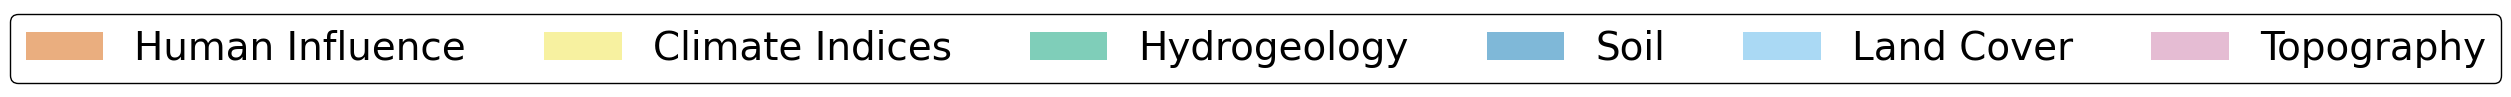

In [7]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

CATEGORY_COLOURS = {
    "Human Influence": "#EAAE7F", # Was #0072B2
    "Climate Indices": "#F7F1A0", # Was #D55E00
    "Hydrogeology": "#7FCEB9",    # Was #009E73
    "Soil": "#7FB8D8",            # Was #F0E442
    "Land Cover": "#AAD9F4",      # Was #CC79A7
    "Topography": "#E5BCD3"       # Was #56B4E9
}



def make_category_legend():
    handles = [
        Patch(facecolor=colour, edgecolor= None, label=category)
        for category, colour in CATEGORY_COLOURS.items()
    ]

    # Increased width from 4 to 12 so all items fit horizontally
    fig, ax = plt.subplots(figsize=(4, 1)) 
    ax.axis('off')  # no axes, just the legend

    legend = ax.legend(
        handles=handles,
        title="",
        frameon=True,
        framealpha=1,
        edgecolor="black",
        loc="center",
        ncol=len(handles), # Dynamically creates a column for every item#
        fontsize=28,         
        title_fontsize=14    
    )

    plt.tight_layout()
    return fig

fig = make_category_legend()
plt.show()

In [8]:
# ── Side-by-side comparison: which variables appear in each? ──────────────────
print(f"\n{'='*60}")
print("  VARIABLE COMPARISON ACROSS DATASETS")
print(f"{'='*60}")

for prefix, label in [('static_', 'Static'), ('temporal_', 'Temporal')]:
    boards = {
        name: make_leaderboard(mean_dfs[name], prefix, N)
        for name in DATASETS
    }

    # Flatten to sets of unique variables per dataset
    sets = {name: set(b.values.flatten()) for name, b in boards.items()}
    names = list(sets)

    only_res    = sets[names[0]] - sets[names[1]]
    only_nonres = sets[names[1]] - sets[names[0]]
    shared      = sets[names[0]] & sets[names[1]]

    print(f"\n── {label} top-{N} overlap ──")
    print(f"  Shared ({len(shared)}):              {sorted(shared)}")
    print(f"  Reservoir only ({len(only_res)}):    {sorted(only_res)}")
    print(f"  Non-Reservoir only ({len(only_nonres)}): {sorted(only_nonres)}")

    # Rank comparison for shared variables
    if shared:
        rows = []
        for var in sorted(shared):
            row = {'variable': var}
            for name, b in boards.items():
                flat = list(b.values.flatten())
                # find first rank (column) where this var appears in any model row
                for model in b.columns:
                    col_vals = b[model].tolist()
                    if var in col_vals:
                        row[f'{name} rank ({model})'] = col_vals.index(var) + 1
            rows.append(row)
        display(pd.DataFrame(rows).set_index('variable'))


# ── Temporal feature plots ────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(18, 6), sharey=True)

for ax, (name, df) in zip(axes, DATASETS.items()):
    plt.sca(ax)
    plot_temporal_feature(df, FEATURE, name)

plt.suptitle(f"Temporal Gradient Importance: {FEATURE}", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()


  VARIABLE COMPARISON ACROSS DATASETS


NameError: name 'make_leaderboard' is not defined

In [ ]:
def prep_temporal_data(df):
    """Converts wide gradient data into a flexible, long-format DataFrame."""
    
    # 1. Bring 'model' and 'sample_idx' back to standard columns if they are in the index
    if 'model' in df.index.names:
        working_df = df.reset_index()
    else:
        working_df = df.copy()
        
    # 2. Isolate only the temporal columns (ignoring static features)
    temporal_cols = [c for c in working_df.columns if c.startswith('temporal__')]
    
    # 3. Melt from Wide to Long format
    long_df = working_df.melt(
        id_vars=['model', 'sample_idx'], 
        value_vars=temporal_cols,
        var_name='raw_column', 
        value_name='importance'
    )
    
    # 4. Extract the variable name and the day number into their own columns
    # Matches the pattern: temporal__{variable}_day_{N}
    extracted = long_df['raw_column'].str.extract(r'temporal__(.*)_day_(\d+)')
    long_df['variable'] = extracted[0]
    long_df['day'] = extracted[1].astype(int)
    
    # 5. Clean up
    return long_df.drop(columns=['raw_column'])



In [ ]:
res_long_data = prep_temporal_data(res_df)
nonres_long_data = prep_temporal_data(nonres_df)

res_long_data

In [ ]:
res_var_importance_df = res_long_data.pivot_table(
    index='variable', 
    columns='model', 
    values='importance', 
    aggfunc='mean' # Use mean to average across samples, summing over days
)
# To mathematically sum all the days together per variable instead of averaging:
res_var_importance_summed = res_var_importance_df.groupby('variable').sum()

nonres_var_importance_df = nonres_long_data.pivot_table(
    index='variable', 
    columns='model', 
    values='importance', 
    aggfunc='mean' # Use mean to average across samples, summing over days
)

nonres_var_importance_summed = nonres_var_importance_df.groupby('variable').sum()


In [ ]:
def get_base_variable(var_name):
    """Maps a specific variable name to its base category."""
    if var_name.startswith('precipitation'):
        return 'precipitation'
    elif var_name.startswith('temperature'):
        return 'temperature'
    elif var_name.startswith('peti'): # Must come before 'pet'
        return 'peti'
    elif var_name.startswith('pet') and var_name != 'peti': 
        return 'pet'
    else:
        # Leaves humidity, windspeed, longwave_rad, shortwave_rad as they are
        return var_name 

# Group using the function and sum the values
res_combined_importance = res_var_importance_summed.groupby(get_base_variable).sum()
res_combined_importance['average_importance'] = res_combined_importance.mean(axis=1)

# 2. Sort the DataFrame by this new column in descending order
res_combined_importance = res_combined_importance.sort_values(by='average_importance', ascending=False)

# Display the result
res_combined_importance

In [ ]:
# Group using the function and sum the values
nonres_combined_importance = nonres_var_importance_summed.groupby(get_base_variable).sum()
nonres_combined_importance['average_importance'] = nonres_combined_importance.mean(axis=1)

# 2. Sort the DataFrame by this new column in descending order
nonres_combined_importance = nonres_combined_importance.sort_values(by='average_importance', ascending=False)

# Display the result
nonres_combined_importance

In [ ]:
nonres_decay_df = non
    res_long_data.pivot_table(
    index='day', 
    columns='model', 
    values='importance', 
    aggfunc='mean'
)
nonres_decay_df

res_decay_df = res_long_data.pivot_table(
    index='day', 
    columns='model', 
    values='importance', 
    aggfunc='mean'
)
res_decay_df

In [ ]:
res_variable_time_df = res_long_data.pivot_table(
    index='day', 
    columns=['model', 'variable'], 
    values='importance', 
    aggfunc='mean'
)

res_variable_time_df


nonres_variable_time_df = nonres_long_data.pivot_table(
    index='day', 
    columns=['model', 'variable'], 
    values='importance', 
    aggfunc='mean'
)

nonres_variable_time_df